<a href="https://colab.research.google.com/github/Briggernaut/MusicLeagueAnalysis/blob/main/MusicLeagueAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, sys
if 'google.colab' in sys.modules:
    if not os.path.exists('MusicLeagueAnalysis'):
        !git clone https://github.com/Briggernaut/MusicLeagueAnalysis
    %cd MusicLeagueAnalysis

Cloning into 'MusicLeagueAnalysis'...
remote: Enumerating objects: 39, done.
remote: Counting objects: 100% (39/39), done.
remote: Compressing objects: 100% (38/38), done.
remote: Total 39 (delta 12), reused 16 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (39/39), 845.14 KiB | 5.60 MiB/s, done.
Resolving deltas: 100% (12/12), done.
/content/MusicLeagueAnalysis/MusicLeagueAnalysis


In [51]:
#@title Read in Data
#load dataframes
import pandas as pd
import ipywidgets as widgets
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np

SEASON = "All" #@param ["All", "Season 1", "Season 2"] {allow-input: true}
DATA_DIR = "data"

#formatting
BOLD = '\033[1m'
RESET = '\033[0m'

# Convenience functions, move to lib
def get_player_name_from_id(id):
    return competitors_df.loc[competitors_df['ID']==id,'Name'].values[0]

def get_round_name_from_id(id):
    return rounds_df.loc[rounds_df['ID']==id,'Name'].values[0]

# Find every folder that has the four needed CSVs
REQUIRED = ['competitors.csv', 'rounds.csv', 'submissions.csv', 'votes.csv']
def getSeasons():
  out = []
  for d in os.listdir(DATA_DIR):
    if os.path.isdir(os.path.join(DATA_DIR, d)):
      for f in REQUIRED:
        if not os.path.exists(os.path.join(DATA_DIR, d, f)):
          break
      else:
        out.append(d)
  return out

available_seasons = sorted(getSeasons())
print('Available seasons:', available_seasons)

if SEASON == "All":
    selected_seasons = available_seasons
elif SEASON in available_seasons:
    selected_seasons = [SEASON]

print('Selected seasons:', selected_seasons)

def load_seasons(filename):
    frames = []
    for season in selected_seasons:
        df = pd.read_csv(os.path.join(DATA_DIR, season, filename))
        df['Season'] = season
        frames.append(df)
    return pd.concat(frames, ignore_index=True)

competitors_df = load_seasons('competitors.csv')
rounds_df = load_seasons('rounds.csv')
submissions_df = load_seasons('submissions.csv')
votes_df = load_seasons('votes.csv')

# convenience definitions
playerIds = competitors_df['ID']
roundIds = rounds_df['ID']

# submissions_df does not have a unique key, make one for easier lookups
submissions_df['uid'] = submissions_df['Spotify URI'] + ' ' + submissions_df['Round ID']
votes_df['uid'] = votes_df['Spotify URI'] + ' ' + votes_df['Round ID']

# Add a column in votes_df for submitted_by_id
lookup_series = submissions_df.set_index('uid')['Submitter ID']
votes_df['Submitter ID'] = votes_df['uid'].map(lookup_series)

# Print Datafram column headers
print('Competitors: ',competitors_df.columns.to_numpy().tolist())
print('Rounds: ',rounds_df.columns.to_numpy().tolist())
print('Submissions: ',submissions_df.columns.to_numpy().tolist())
print('Votes: ',votes_df.columns.to_numpy().tolist())

Available seasons: ['Season 1', 'Season 2']
Selected seasons: ['Season 1', 'Season 2']
Competitors:  ['ID', 'Name', 'Season']
Rounds:  ['ID', 'Created', 'Name', 'Description', 'Playlist URL', 'Season']
Submissions:  ['Spotify URI', 'Title', 'Album', 'Artist(s)', 'Submitter ID', 'Created', 'Comment', 'Round ID', 'Visible To Voters', 'Season', 'uid']
Votes:  ['Spotify URI', 'Voter ID', 'Created', 'Points Assigned', 'Comment', 'Round ID', 'Season', 'uid', 'Submitter ID']


In [ ]:
#@title Songs Submitted by Each User (interactive)
#list of songs submitted by each user
songs_submitted = {}
for player in playerIds:
    # Returns the title and artist of every submission from player
    song_list = submissions_df.loc[submissions_df['Submitter ID'] == player, ['Title','Artist(s)']]
    # smush the artist and title together
    song_list['formatted'] = song_list['Title'].str.cat(song_list['Artist(s)'], sep=' by ')
    # turn player id to player name
    player_name = get_player_name_from_id(player)
    # drop the ide field
    song_list = song_list.iloc[:, 1:]
    # dict of list of songs index by player name
    songs_submitted[player_name] = song_list['formatted'].tolist()

#sort the dict alphabetically to make it pretty
songs_submitted = dict(sorted(songs_submitted.items()))

# Define the event handler function for drop down
def on_change(change):
    if change['type'] == 'change' and change['name'] == 'value':
        with output:
            output.clear_output() # Clear previous text
            print(f"{BOLD}Player {change['new']} submitted the following songs:{RESET}")
            print(*songs_submitted[change['new']], sep="\n")

# Create the dropdown
dropdown = widgets.Dropdown(
    options=list(songs_submitted),
    description='Select a player:',
    style={'description_width': 'initial'},
    disabled=False,
)
output = widgets.Output()

# Bind the function to the dropdown's value changes
dropdown.observe(on_change)

# Display both the dropdown and the output container
display(dropdown, output)

Dropdown(description='Select a player:', options=('Adam Kestian', 'Brigette', 'De Wolfe', 'Eric Anderson', 'Hm…

Output()

In [ ]:
#@title Calculate player stats
player_votes_stats = []
for player in playerIds:
    # Sum all votes given to a player
    totalVotes = votes_df.loc[votes_df['Submitter ID'] == player, 'Points Assigned'].sum()
    # find the number of rounds they participated in
    count = (submissions_df['Submitter ID'] == player).sum()
    #print (player +' got '+ str(totalVotes) +' votes '+' and participated in '+str(count)+'rounds')
    # Append simple dictionaries to a list
    player_votes_stats.append({'Name': get_player_name_from_id(player), 'Votes For': totalVotes, 'Rounds Participated':count})

# Convert the whole list to a DataFrame all at once
player_stat_df = pd.DataFrame(player_votes_stats)
player_stat_df['Votes per Round'] = player_stat_df['Votes For']/player_stat_df['Rounds Participated']


## Votes per Round


In [ ]:
#@title Display list of best votes per round
# sort by votes/round
display_df = player_stat_df[['Name', 'Votes per Round']].sort_values(by='Votes per Round', ascending=False)
# display list
display(display_df.style.hide(axis="index"))

Name,Votes per Round
Mariah,29.333333
mandeepkundal,27.750000
chlo,25.125000
Isaiah Freed,24.250000
De Wolfe,23.812500
Matoos,21.769231
William Dullemond,21.562500
the only John,21.416667
Mick,20.937500
shannon_ar,20.384615


Players with perfect attendance:
Pascal
Mick
William Dullemond
Brigette
darkknave
Adam Kestian
JustLisa

Players who forgot to vote after having submitted a song:


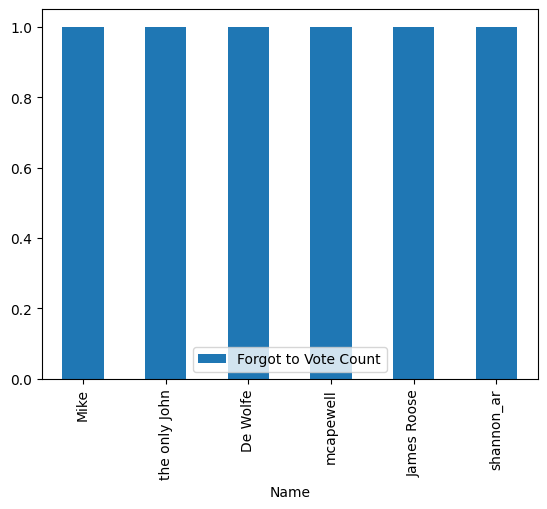

In [ ]:
#@title Calculate participation stats
# How many rounds did each player not submit or not vote in?
player_attendance_stats=[]
for player in playerIds:
    rounds_submitted = submissions_df.loc[(submissions_df['Submitter ID'] == player),'Round ID'].tolist()
    rounds_not_submitted  = list(set(roundIds) - set(rounds_submitted))
    # rounds where user submitted but did not vote
    rounds_voted = votes_df.loc[(votes_df['Voter ID'] == player),'Round ID'].tolist()
    # list of rounds, remove those where user voted, remove those where the user did not submit
    rounds_forgot_to_vote = list(set(roundIds) - set(rounds_voted)-set(rounds_not_submitted))
    #convert ids to names
    rounds_submitted = [get_round_name_from_id(round_id) for round_id in rounds_submitted]
    rounds_not_submitted = [get_round_name_from_id(round_id) for round_id in rounds_not_submitted]
    rounds_forgot_to_vote = [get_round_name_from_id(round_id) for round_id in rounds_forgot_to_vote]
    player_attendance_stats.append({'Name': get_player_name_from_id(player), 'Rounds Not Submitted': rounds_not_submitted, 'Forgot to Vote':rounds_forgot_to_vote, 'Perfect Attendance':(len(rounds_not_submitted)==0 and len(rounds_forgot_to_vote)==0) })
player_attendance_df = pd.DataFrame(player_attendance_stats)
#makea column counting how many rounds a player forgot to vote
player_attendance_df['Forgot to Vote Count'] = player_attendance_df['Forgot to Vote'].str.len()
#print(player_attendance_df)
perfect_attendance_list = player_attendance_df.loc[(player_attendance_df['Perfect Attendance'] == True),'Name'].tolist()
print(f"{BOLD}Players with perfect attendance:{RESET}")
print(*perfect_attendance_list, sep="\n")

print(f"\n{BOLD}Players who forgot to vote after having submitted a song:{RESET}")
display_df = player_attendance_df.loc[(player_attendance_df['Forgot to Vote Count'] > 0)].sort_values(by='Forgot to Vote Count', ascending=False)
display_df.plot.bar(x='Name', y='Forgot to Vote Count', rot=90);

Name,Winner,Highest Score,Average Score,Most Votes,Submitted Last,Voted Last
Water,JustLisa,16,10.000000,4,James Roose,mcapewell
Favourite song released before you were born,Pascal,16,10.000000,4,James Roose,Hman
getting ready to win something / pump you up music,the only John,28,15.000000,6,James Roose,jammbler
Nostalgia,De Wolfe,32,20.000000,7,shannon_ar,the only John
Songs with a location in the title of the song or name of the band,mandeepkundal,30,20.000000,8,shannon_ar,the only John
Movie Soundtrack,JustLisa,26,20.000000,6,Hman,James Roose
Epic Openers! (favorite 1st track of any album),Matoos,37,20.000000,7,James Roose,mcapewell
Beatboxing,mandeepkundal,40,20.000000,9,shannon_ar,chlo
Great Song Covers,mandeepkundal,33,19.000000,10,the only John,chlo
Your theme if you were a supervillain,Mick,35,18.947368,5,Puneesh,Eric Anderson


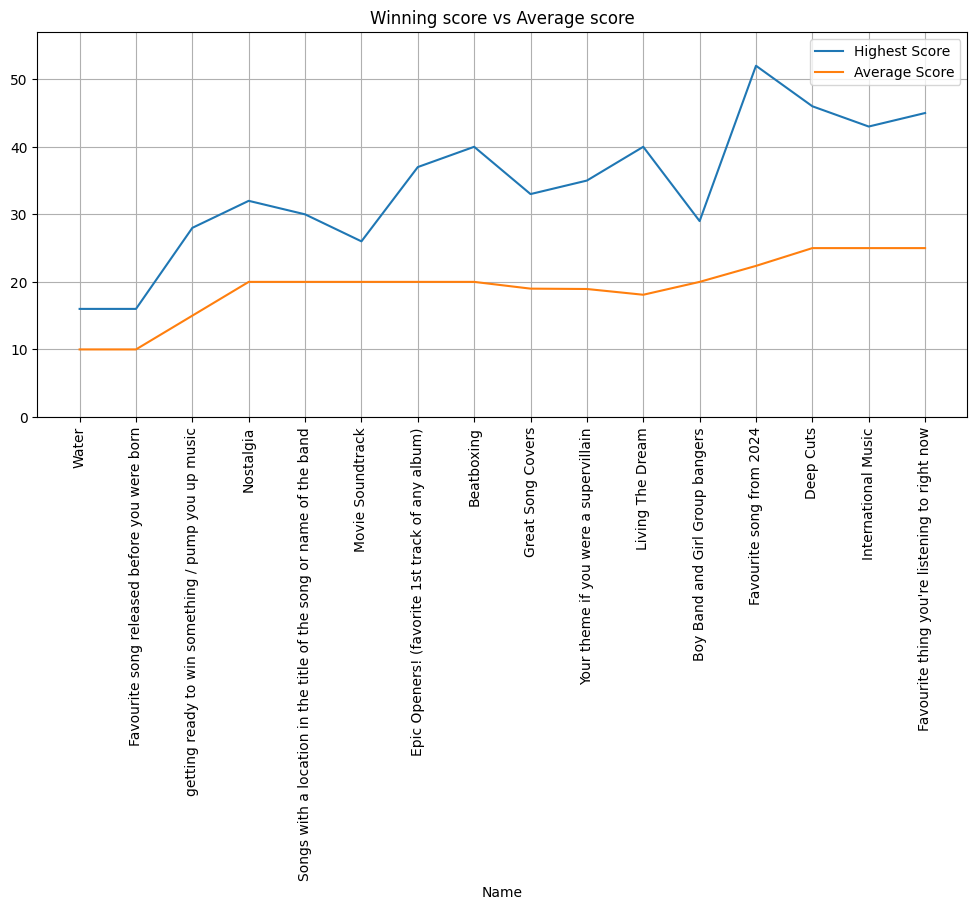

In [ ]:
#@title Calculate Round stats
# Round stats who submitted last, who voted last, most votes given by a single person
round_stats = []
for roundId in roundIds:
    voted_last = get_player_name_from_id(votes_df.loc[votes_df[votes_df['Round ID'] == roundId]['Created'].idxmax(), 'Voter ID'])
    submitted_last = get_player_name_from_id(submissions_df.loc[submissions_df[submissions_df['Round ID'] == roundId]['Created'].idxmax(), 'Submitter ID'])
    #print ("voted last "+voted_last)
    #print ("submitted last "+submitted_last)
    most_points = votes_df.loc[votes_df[votes_df['Round ID'] == roundId]['Points Assigned'].idxmax(), 'Points Assigned']
    #print ("most points "+str(most_points))
    #gives us a df with URI and sum of votes
    round_results = votes_df.loc[votes_df['Round ID'] == roundId].groupby('Spotify URI', as_index=False)['Points Assigned'].sum()
    #print(round_results)
    ave_points_per_song= round_results['Points Assigned'].mean()
    #print ("average points per song "+str(ave_points_per_song))
    highest_score = round_results['Points Assigned'].max()
    #print('highest score '+str(highest_score))
    #get winner name from highest score
    winning_song = round_results.loc[round_results['Points Assigned']==highest_score,'Spotify URI'].values[0]
    #print('Winning song ' +winning_song)
    winner =  get_player_name_from_id(submissions_df.loc[(submissions_df['Round ID'] == roundId) & (submissions_df['Spotify URI'] == winning_song),'Submitter ID'].values[0])
    #TODO: need to score tiebreak by # voters, create a whole rank column for use later
    #print('Winner '+winner)
    round_stats.append({'Name': get_round_name_from_id(roundId), 'Winner': winner, 'Highest Score':highest_score, 'Average Score':ave_points_per_song, 'Most Votes':most_points,'Submitted Last': submitted_last, 'Voted Last':voted_last})

round_stats_df = pd.DataFrame(round_stats)
display(round_stats_df.style.hide(axis="index"))
score_v_average = round_stats_df[['Name', 'Highest Score','Average Score']]
ax= score_v_average.set_index('Name').plot.line(title='Winning score vs Average score', grid=True,figsize=(12, 5),ylim=(0, score_v_average['Highest Score'].max() + 5))
ax.set_xticks(np.arange(len(score_v_average)))
ax.set_xticklabels(score_v_average.Name, rotation=90)
plt.show()


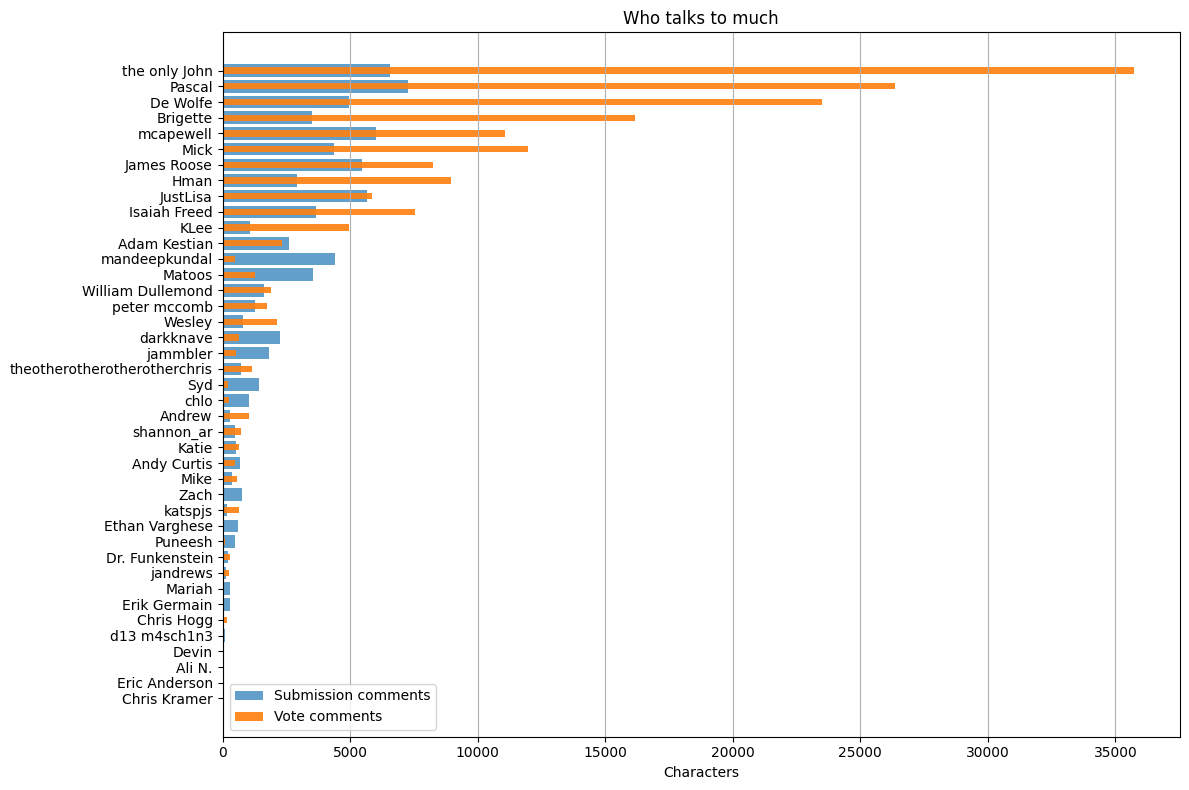

In [ ]:
#@title Who Talks the Most
# Total characters each player wrote in submission comments and in voting comments overlaying each other

submission_chars = (submissions_df.assign(Chars=submissions_df['Comment'].fillna('').astype(str).str.len())
                    .groupby('Submitter ID')['Chars'].sum())
vote_chars = (votes_df.assign(Chars=votes_df['Comment'].fillna('').astype(str).str.len())
              .groupby('Voter ID')['Chars'].sum())

# Combine into one table - should add no char players
chars_df = pd.DataFrame({'Submissions': submission_chars, 'Votes': vote_chars}).fillna(0)
chars_df.index = [get_player_name_from_id(p) for p in chars_df.index]
chars_df = chars_df.loc[(chars_df['Submissions'] + chars_df['Votes']).sort_values().index]  # sort by verbosity

y = np.arange(len(chars_df))
fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(y, chars_df['Submissions'], height=0.8, label='Submission comments', alpha=0.7)
ax.barh(y, chars_df['Votes'], height=0.4, label='Vote comments', color='tab:orange', alpha=0.9)
ax.set_yticks(y)
ax.set_yticklabels(chars_df.index)
ax.set_xlabel('Characters')
ax.set_title('Who talks to much')
ax.grid(True, axis='x')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# player stats (best round [placement or votes], worst round, who gave you most/least votes, rounds missed
# graph of votes received over round (with a running average line)
# rounds won
# number of comments left
# most emojis? count
# what place did they get in their own round?

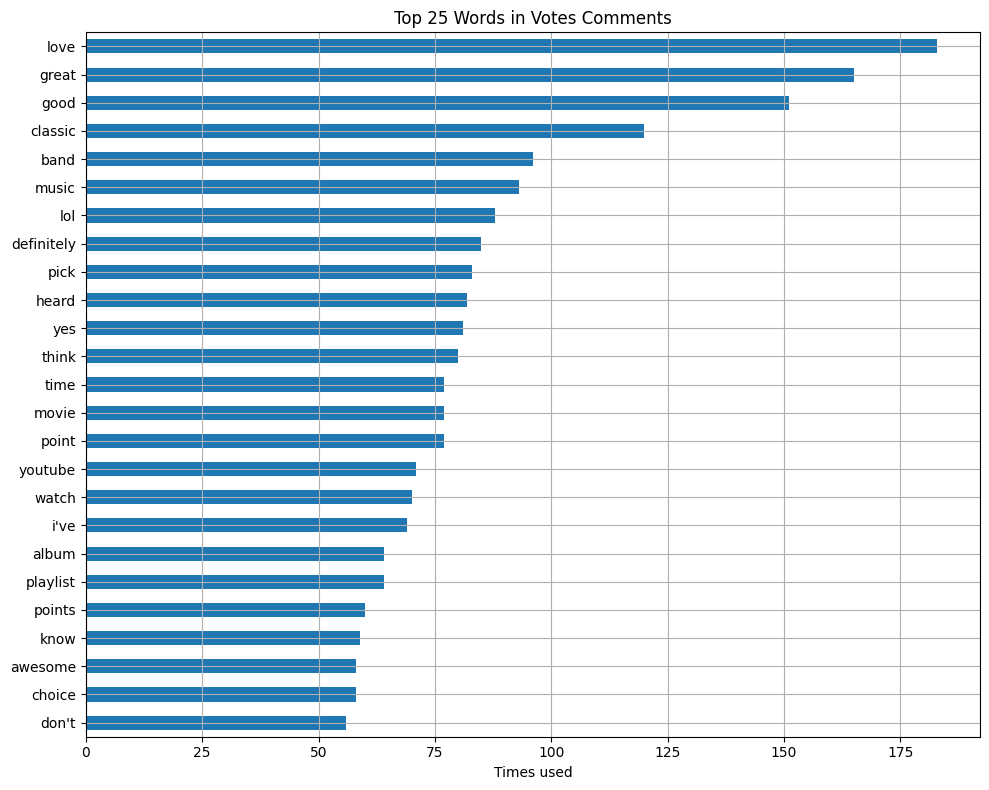

In [45]:
#@title Most Common Words in Comments
import re
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

source = "Votes"  #@param ["Both", "Submissions", "Votes"]
top_n = 25  #@param {type:"integer"}
extra_stopwords = "song, songs, just, really, like, it's, com, https, i'm"  #@param {type:"string"}

stopwords = set(ENGLISH_STOP_WORDS) | {w.strip().lower() for w in extra_stopwords.split(',') if w.strip()}

def get_words(text):
    words = re.findall(r"[a-z']+", str(text).lower())
    words = [w.strip("'") for w in words]
    return [w for w in words if len(w) > 2 and w not in stopwords]

# Gather the comments
comments = []
if source in ("Both", "Submissions"):
    comments.append(submissions_df['Comment'])
if source in ("Both", "Votes"):
    comments.append(votes_df['Comment'])
all_comments = pd.concat(comments).dropna()

# Count words across every comment
word_counts = Counter(w for comment in all_comments for w in get_words(comment))
top_words = pd.Series(dict(word_counts.most_common(top_n))).sort_values()

ax = top_words.plot.barh(figsize=(10, 8), grid=True, title=f'Top {top_n} Words in {source} Comments')
ax.set_xlabel('Times used')
plt.tight_layout()
plt.show()

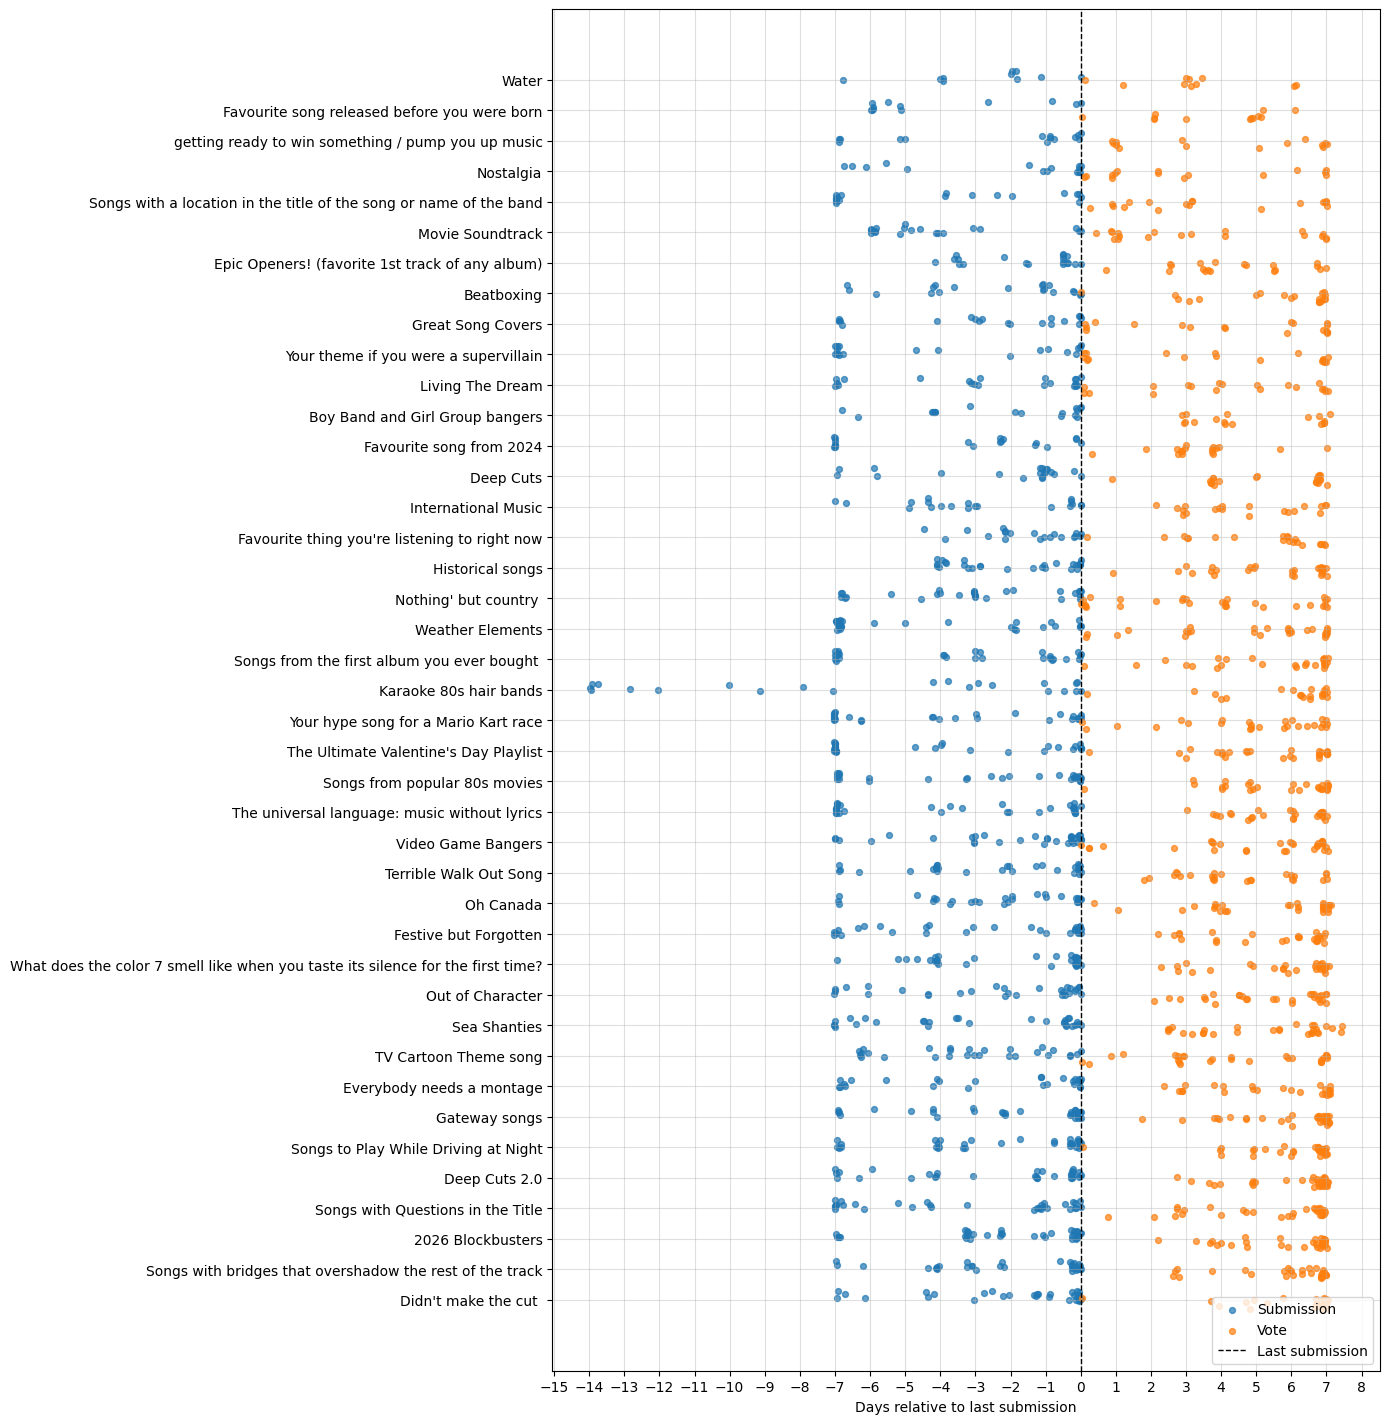

In [68]:
#@title Submission & Voting Timing
import numpy as np
from matplotlib.ticker import MultipleLocator

subs = submissions_df[['Round ID', 'Created']].copy()
subs['Created'] = pd.to_datetime(subs['Created'], utc=True)
votes = votes_df[['Round ID', 'Voter ID', 'Created']].copy()
votes['Created'] = pd.to_datetime(votes['Created'], utc=True)
votes = votes.groupby(['Round ID', 'Voter ID'], as_index=False)['Created'].max()

# Anchor every round on its last submission (time 0)
last_sub = subs.groupby('Round ID')['Created'].max().rename('Last submission')
subs = subs.join(last_sub, on='Round ID')
votes = votes.join(last_sub, on='Round ID').dropna(subset=['Last submission'])
subs['Days'] = (subs['Created'] - subs['Last submission']).dt.total_seconds() / 86400
votes['Days'] = (votes['Created'] - votes['Last submission']).dt.total_seconds() / 86400

# Sort the rounds
round_dates = rounds_df.set_index('ID')['Created'].pipe(pd.to_datetime, utc=True)
round_dates = round_dates.reindex(last_sub.index).fillna(subs.groupby('Round ID')['Created'].min())
round_order = round_dates.sort_values().index
round_names = {r: f'Round {i + 1}' for i, r in enumerate(round_order)}
round_names.update(rounds_df.set_index('ID')['Name'].to_dict())

fig, ax = plt.subplots(figsize=(14, max(4, 0.35 * len(round_order))))

# Grid
jitter = np.random.default_rng(0).uniform(-0.35, 0.35, size=len(subs) + len(votes))
ax.scatter(subs['Days'], subs['Round ID'].map(y_pos) - 0.12 + jitter[:len(subs)] * 0.5,
           s=18, alpha=0.7, label='Submission')
ax.scatter(votes['Days'], votes['Round ID'].map(y_pos) + 0.12 + jitter[len(subs):] * 0.5,
           s=18, alpha=0.7, label='Vote')
ax.axvline(0, color='black', linestyle='--', linewidth=1, label='Last submission')
ax.set_yticks(range(len(round_order)))
ax.set_yticklabels([round_names.get(r, r) for r in round_order])
ax.invert_yaxis()
ax.xaxis.set_major_locator(MultipleLocator(1))  # a gridline every day
ax.set_xlabel('Days relative to last submission')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

Ordered by: Submission time
Songs: 1010   Rounds: 41
Spearman ρ = -0.124   p = 0.000   (significant)
First → last song: -3.77 points vs. round average

     mean   sem  count
Bin                   
1    1.25  0.66    217
2    0.87  0.76    194
3    0.02  0.73    192
4   -0.26  0.73    194
5   -1.84  0.63    213


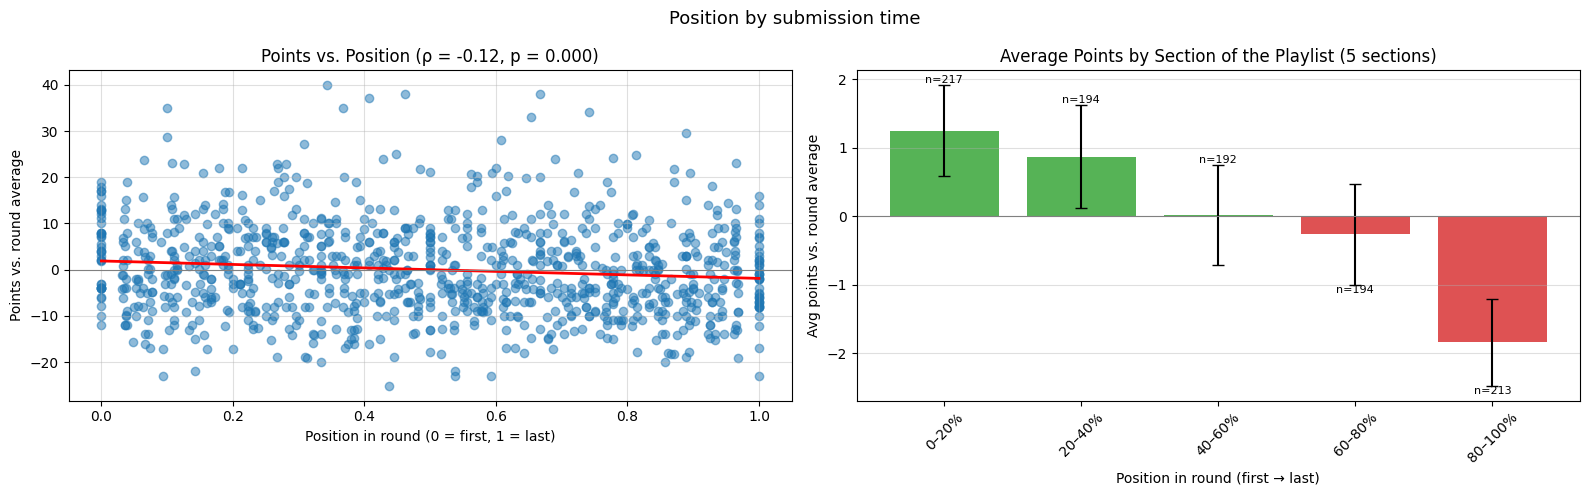

In [93]:
#@title Points vs Time Submited/Playlist position
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

order_by = "Submission time"  #@param ["Submission time", "Data order"]
n_bins = 5  #@param {type:"slider", min:2, max:20, step:1}

# Total points per song
points = (votes_df.groupby(['Round ID', 'Spotify URI'])['Points Assigned']
          .sum().rename('Points').reset_index())

# Position of each song within its round (1 = first)
df = submissions_df[['Round ID', 'Spotify URI', 'Created']].copy()
if order_by == "Submission time":
    df['Created'] = pd.to_datetime(df['Created'])
    df['Position'] = df.groupby('Round ID')['Created'].rank(method='first')
else:
    # Order the rows appear in submissions_df
    df['Position'] = df.groupby('Round ID').cumcount() + 1

# Scale position to 0 (first) to 1 (last) so rounds of different sizes line up
size = df.groupby('Round ID')['Position'].transform('max')
df['Rel Pos'] = (df['Position'] - 1) / (size - 1).clip(lower=1)

# Songs with no votes get 0 points
df = df.merge(points, on=['Round ID', 'Spotify URI'], how='left').fillna({'Points': 0})

# Points relative to the round average, so rounds with more points don't skew the result
df['Points vs Avg'] = df['Points'] - df.groupby('Round ID')['Points'].transform('mean')

# Correlation and trend
rho, p = stats.spearmanr(df['Rel Pos'], df['Points vs Avg'])
slope, intercept = np.polyfit(df['Rel Pos'], df['Points vs Avg'], 1)

# Average by section of the playlist (1 = first section, n_bins = last)
df['Bin'] = pd.cut(df['Rel Pos'], bins=np.linspace(0, 1, n_bins + 1),
                   labels=range(1, n_bins + 1), include_lowest=True)
by_bin = df.groupby('Bin', observed=True)['Points vs Avg'].agg(['mean', 'sem', 'count'])

print(f'Ordered by: {order_by}')
print(f'Songs: {len(df)}   Rounds: {df["Round ID"].nunique()}')
print(f'Spearman ρ = {rho:+.3f}   p = {p:.3f}   '
      f'({"significant" if p < 0.05 else "not significant"})')
print(f'First → last song: {slope:+.2f} points vs. round average\n')
print(by_bin.round(2))

# Plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle(f'Position by {order_by.lower()}', fontsize=13)

# Left: scatter with trend line
ax1.scatter(df['Rel Pos'], df['Points vs Avg'], alpha=0.5)
ax1.plot([0, 1], [intercept, slope + intercept], color='red', linewidth=2)
ax1.axhline(0, color='gray', linewidth=0.8)
ax1.set_xlabel('Position in round (0 = first, 1 = last)')
ax1.set_ylabel('Points vs. round average')
ax1.set_title(f'Points vs. Position (ρ = {rho:+.2f}, p = {p:.3f})')
ax1.grid(True, alpha=0.4)

# Right: average by section
x = by_bin.index.astype(int)
colors = ['tab:green' if m >= 0 else 'tab:red' for m in by_bin['mean']]
ax2.bar(x, by_bin['mean'], yerr=by_bin['sem'], capsize=4, color=colors, alpha=0.8)
ax2.axhline(0, color='gray', linewidth=0.8)
for xi, (m, s, n) in zip(x, by_bin.values):
    ax2.text(xi, m + (s if m >= 0 else -s), f'n={int(n)}',
             ha='center', va='bottom' if m >= 0 else 'top', fontsize=8)
ax2.set_xticks(range(1, n_bins + 1))
ax2.set_xticklabels([f'{100*(i-1)/n_bins:.0f}–{100*i/n_bins:.0f}%'
                     for i in range(1, n_bins + 1)], rotation=45)
ax2.set_xlabel('Position in round (first → last)')
ax2.set_ylabel('Avg points vs. round average')
ax2.set_title(f'Average Points by Section of the Playlist ({n_bins} sections)')
ax2.grid(True, axis='y', alpha=0.4)

plt.tight_layout()
plt.show()

# New Section